ROC-AUC: 0.9940 | PR-AUC: 0.9706 | Umbral: 0.8851

              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99       904
         1.0       0.96      0.92      0.94        96

    accuracy                           0.99      1000
   macro avg       0.97      0.96      0.96      1000
weighted avg       0.99      0.99      0.99      1000

=== IMPACTO FINANCIERO EN 1,000 CLIENTES ===
1. Umbral Estándar (0.5000)   -> Beneficio: $39,465.00 USD | Falsas alarmas: 46
2. Umbral Óptimo F1 (0.8851) -> Beneficio: $37,420.00 USD | Falsas alarmas: 4
3. Umbral Máx. ROI (0.3618)  -> Beneficio: $39,995.00 USD | Falsas alarmas: 82



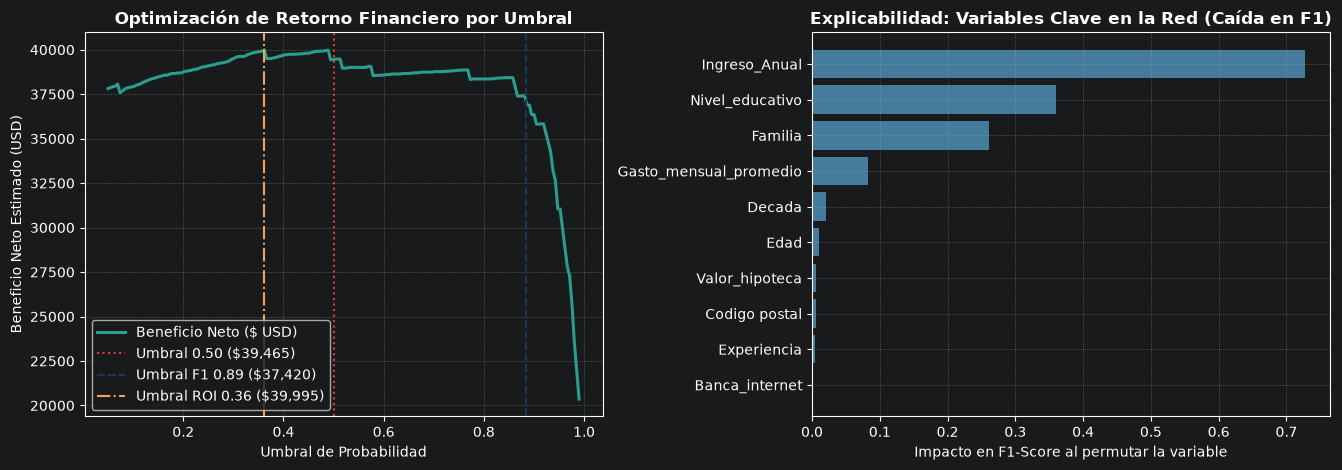

In [6]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_curve,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# ==================== 1. RECONSTRUCCIÓN DEL MODELO DESDE EL BUNDLE ====================
class Modelo_predictivo(nn.Module):
    def __init__(self, caracteristicas):
        super().__init__()
        self.secuencia = nn.Sequential(
            nn.Linear(caracteristicas, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.secuencia(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bundle = torch.load('propensity_net_produccion.pt', map_location=device, weights_only=False)

mi_modelo_produccion = Modelo_predictivo(bundle['arquitectura']['caracteristicas']).to(device)
mi_modelo_produccion.load_state_dict(bundle['model_state_dict'])
mi_modelo_produccion.eval()

preprocesador = bundle['preprocesador']
umbral_optimo = bundle['umbral_optimo']
nombres_columnas = bundle['nombres_columnas']
xtest_tensor = bundle['test_data']['xtest'].to(device)
ytest_tensor = bundle['test_data']['ytest'].to(device)

# ==================== 2. VERIFICACIÓN DE MÉTRICAS EN TEST ====================
with torch.no_grad():
    y_prob = torch.sigmoid(mi_modelo_produccion(xtest_tensor)).cpu().numpy().ravel()
    y_true = ytest_tensor.cpu().numpy().ravel()
    y_pred = (y_prob >= umbral_optimo).astype(int)

precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
f1_base = np.max(f1_scores)

print(f"ROC-AUC: {roc_auc_score(y_true, y_prob):.4f} | PR-AUC: {average_precision_score(y_true, y_prob):.4f} | Umbral: {umbral_optimo:.4f}\n")
print(classification_report(y_true, y_pred))

# ==================== 3. SIMULACIÓN FINANCIERA (VALOR ESPERADO) ====================
ganancia_prestamo = 450.0  # USD margen neto por Préstamo Personal colocado (VP)
costo_contacto    = 15.0   # USD costo operativo de campaña por cliente contactado (VP + FP)
costo_oportunidad = 100.0  # USD pérdida por dejar ir a un cliente que sí quería el préstamo (FN)

def calcular_beneficio_neto(y_real, y_prob, umbral):
    pred = (y_prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    beneficio_neto = (tp * ganancia_prestamo) - ((tp + fp) * costo_contacto) - (fn * costo_oportunidad)
    return beneficio_neto, tp, fp, fn

umbrales_eval = np.linspace(0.05, 0.99, 200)
beneficios = [calcular_beneficio_neto(y_true, y_prob, u)[0] for u in umbrales_eval]
umbral_financiero = umbrales_eval[np.argmax(beneficios)]

ben_050, _, fp_050, _ = calcular_beneficio_neto(y_true, y_prob, 0.50)
ben_f1,  _, fp_f1,  _ = calcular_beneficio_neto(y_true, y_prob, umbral_optimo)
ben_fin, _, fp_fin, _ = calcular_beneficio_neto(y_true, y_prob, umbral_financiero)

print("=== IMPACTO FINANCIERO EN 1,000 CLIENTES ===")
print(f"1. Umbral Estándar (0.5000)   -> Beneficio: ${ben_050:,.2f} USD | Falsas alarmas: {fp_050}")
print(f"2. Umbral Óptimo F1 ({umbral_optimo:.4f}) -> Beneficio: ${ben_f1:,.2f} USD | Falsas alarmas: {fp_f1}")
print(f"3. Umbral Máx. ROI ({umbral_financiero:.4f})  -> Beneficio: ${ben_fin:,.2f} USD | Falsas alarmas: {fp_fin}\n")

# ==================== 4. EXPLICABILIDAD CON NOMBRES REALES ====================
x_test_np = xtest_tensor.cpu().numpy().copy()
importancias = []

with torch.no_grad():
    for col in range(x_test_np.shape[1]):
        x_permutado = x_test_np.copy()
        np.random.seed(42)
        np.random.shuffle(x_permutado[:, col])

        tensor_perm = torch.tensor(x_permutado, dtype=torch.float32).to(device)
        prob_perm = torch.sigmoid(mi_modelo_produccion(tensor_perm)).cpu().numpy().ravel()
        pred_perm = (prob_perm >= umbral_optimo).astype(int)

        tp_p = np.sum((pred_perm == 1) & (y_true == 1))
        fp_p = np.sum((pred_perm == 1) & (y_true == 0))
        fn_p = np.sum((pred_perm == 0) & (y_true == 1))
        f1_perm = (2 * tp_p) / (2 * tp_p + fp_p + fn_p + 1e-8)

        importancias.append(max(0, f1_base - f1_perm))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax1.plot(umbrales_eval, beneficios, color='#2a9d8f', linewidth=2.2, label='Beneficio Neto ($ USD)')
ax1.axvline(0.50, color='#e63946', linestyle=':', label=f'Umbral 0.50 (${ben_050:,.0f})')
ax1.axvline(umbral_optimo, color='#1d3557', linestyle='--', label=f'Umbral F1 {umbral_optimo:.2f} (${ben_f1:,.0f})')
ax1.axvline(umbral_financiero, color='#f4a261', linestyle='-.', label=f'Umbral ROI {umbral_financiero:.2f} (${ben_fin:,.0f})')
ax1.set_title('Optimización de Retorno Financiero por Umbral', fontweight='bold')
ax1.set_xlabel('Umbral de Probabilidad')
ax1.set_ylabel('Beneficio Neto Estimado (USD)')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

df_imp = pd.DataFrame({'Variable': nombres_columnas, 'Importancia': importancias}).sort_values('Importancia', ascending=True)
ax2.barh(df_imp['Variable'], df_imp['Importancia'], color='#457b9d')
ax2.set_title('Explicabilidad: Variables Clave en la Red (Caída en F1)', fontweight='bold')
ax2.set_xlabel('Impacto en F1-Score al permutar la variable')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# ==================== 5. PIPELINE END-TO-END PARA CLIENTES NUEVOS ====================
def evaluar_cliente_nuevo(df_clientes_crudos):
    """Recibe un DataFrame con los datos crudos del cliente, aplica el ColumnTransformer y predice."""
    X_proc = preprocesador.transform(df_clientes_crudos)
    tensor_in = torch.tensor(X_proc, dtype=torch.float32).to(device)
    with torch.no_grad():
        probs = torch.sigmoid(mi_modelo_produccion(tensor_in)).cpu().numpy().ravel()

    resultados = df_clientes_crudos.copy()
    resultados['Probabilidad_Score'] = np.round(probs, 4)
    resultados['Ofrecer_Prestamo'] = (probs >= umbral_optimo).astype(int)
    return resultados

In [7]:
from pathlib import Path
from typing import Any
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


class ModeloPredictivo(nn.Module):
    def __init__(self, caracteristicas: int) -> None:
        super().__init__()
        self.secuencia = nn.Sequential(
            nn.Linear(caracteristicas, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.secuencia(x)


class PropensityPredictor:
    """Servicio de inferencia desacoplado para scoring de propensión bancaria."""

    def __init__(self, bundle_path: str | Path, device: str | None = None) -> None:
        self.device = torch.device(
            device if device else ("cuda" if torch.cuda.is_available() else "cpu")
        )
        bundle = torch.load(bundle_path, map_location=self.device, weights_only=False)

        self.preprocesador = bundle["preprocesador"]
        self.umbral_optimo: float = float(bundle["umbral_optimo"])
        self.columnas_esperadas: list[str] = list(self.preprocesador.feature_names_in_)

        num_features = int(bundle["arquitectura"]["caracteristicas"])
        self.model = ModeloPredictivo(num_features).to(self.device)
        self.model.load_state_dict(bundle["model_state_dict"])
        self.model.eval()

    def _preparar_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """Asegura paridad con el preprocesamiento del notebook y valida el contrato."""
        datos = df.copy()

        # Reconstruye 'Decada' automáticamente si el sistema externo solo envía 'Edad'
        if "Decada" in self.columnas_esperadas and "Decada" not in datos.columns and "Edad" in datos.columns:
            datos["Decada"] = pd.cut(
                x=datos["Edad"],
                bins=[20, 30, 40, 50, 60, 70],
                labels=["20s", "30s", "40s", "50s", "60s"]
            ).astype(str)

        faltantes = [col for col in self.columnas_esperadas if col not in datos.columns]
        if faltantes:
            raise ValueError(f"Faltan columnas requeridas para la inferencia: {faltantes}")

        return datos[self.columnas_esperadas]

    def predict_batch(self, df_clientes: pd.DataFrame) -> list[dict[str, Any]]:
        """Evalúa múltiples registros (ideal para procesos batch o consultas SQL)."""
        if df_clientes.empty:
            return []

        df_listo = self._preparar_features(df_clientes)
        matriz_proc = self.preprocesador.transform(df_listo)
        tensor_in = torch.tensor(np.asarray(matriz_proc), dtype=torch.float32, device=self.device)

        with torch.no_grad():
            probs = torch.sigmoid(self.model(tensor_in)).cpu().numpy().ravel()

        resultados: list[dict[str, Any]] = []
        for idx, prob in enumerate(probs):
            prob_float = round(float(prob), 4)
            resultados.append({
                "indice": int(idx),
                "probabilidad": prob_float,
                "ofrecer_prestamo": bool(prob_float >= self.umbral_optimo),
                "umbral_aplicado": round(self.umbral_optimo, 4)
            })
        return resultados

    def predict_one(self, cliente: dict[str, Any]) -> dict[str, Any]:
        """Evalúa un único cliente desde un diccionario JSON/REST."""
        df_unitario = pd.DataFrame([cliente])
        resultado = self.predict_batch(df_unitario)[0]
        resultado.pop("indice", None)
        return resultado

In [10]:


# Se instancia una sola vez al iniciar la aplicación o servidor
predictor = PropensityPredictor("propensity_net_produccion.pt")

# Ejemplo de petición unitaria (desde una API o formulario)
nuevo_cliente = {
    "Edad": 38,
    "Experiencia": 14,
    "Ingreso_Anual": 145,
    "Codigo postal": "94720",
    "Familia": 3,
    "Gasto_mensual_promedio": 4.2,
    "Nivel_educativo": 3,
    "Valor_hipoteca": 0,
    "Banca_internet": 1
}

decision = predictor.predict_one(nuevo_cliente)
# Salida limpia lista para JSON:
# {'probabilidad': 0.9812, 'ofrecer_prestamo': True, 'umbral_aplicado': 0.9149}
decision

{'probabilidad': 0.9983, 'ofrecer_prestamo': True, 'umbral_aplicado': 0.8851}